# Lab 6. Matrices
Hardware 1 - Mathematics Python Labs<br>
Information and Communication Technology<br>
Metropolia University of Applied Sciences

## Setup

Remember add your `name`, `student_id`, and `date_returned`.

Read necessary libraries and functions.

**Remember to download lab6.py from OMA to your project folder!**

In [1]:
name = "Yehor"
student_id = 2602063 # Write your student number here
date_returned = "11.09.2026"

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import lab6 # REMEMBER TO LOAD THIS FILE IN THE SAME DIRECTORY AS THIS NOTEBOOK

---
## Problem 1

In this problem the aim is to practise matrix multiplication (dot product). The matrices A and B generated by the code. Your task is:

1. Calculate the matrix dot product $C = AB$, and print it out with 4 decimals.
2. Calculate the matrix dot product  $D = BA$ and print it out with 4 decimals.
3. Compare C and D
4. Based on these results, what can you say about A and B?

Tips
- Study `numpy.isclose()` and `numpy.allclose()` and use them for comparison
- Use `numpy.round()` to round the results of dot product to few decimals. 


In [3]:
# Load matrices A and B for the problem 1
A, B = lab6.problem1(student_id)
# Print them
print('A = \n', A)
print('B = \n', B)

A = 
 [[0.1159867  0.07732447 0.03866223 0.15464893 0.03866223]
 [0.1159867  0.30929787 0.1159867  0.19331117 0.15464893]
 [0.30929787 0.15464893 0.15464893 0.07732447 0.27063564]
 [0.15464893 0.30929787 0.1159867  0.27063564 0.07732447]
 [0.07732447 0.27063564 0.1159867  0.3479601  0.3479601 ]]
B = 
 [[ 22.27103182  18.32352089  -1.41403377 -18.44135704  -5.42046277]
 [ 16.9684052   26.27746083  -4.77236396 -20.20889925  -5.3615447 ]
 [-76.88808606 -78.65562826  15.96679795  77.83077523  13.78682922]
 [ -1.82646028 -10.19282673  -0.29459037   8.01285801   3.18157597]
 [  9.30905563  11.90145087  -1.00160725 -14.14033767   0.47134459]]


In [4]:
# Task 1: Calculate C = AB
np.set_printoptions(precision=4, suppress=True, floatmode='fixed')

C = np.round(A @ B, 4)
print('C =\n', C + 0.0)

C =
 [[1.0000 0.0000 0.0000 0.0000 0.0000]
 [0.0000 1.0000 0.0000 0.0000 0.0000]
 [0.0000 0.0000 1.0000 0.0000 0.0000]
 [0.0000 0.0000 0.0000 1.0000 0.0000]
 [0.0000 0.0000 0.0000 0.0000 1.0000]]


In [5]:
# Task 2: Calculate D = BA
D = np.round(B @ A, 4)
print('D =\n', D + 0.0)

D =
 [[1.0000 0.0000 0.0000 0.0000 0.0000]
 [0.0000 1.0000 0.0000 0.0000 0.0000]
 [0.0000 0.0000 1.0000 0.0000 0.0000]
 [0.0000 0.0000 0.0000 1.0000 0.0000]
 [0.0000 0.0000 0.0000 0.0000 1.0000]]


In [6]:
# Task 3: Compare C and D
are_equal = np.allclose(C, D)
print("Are C and D equal?", are_equal)

Are C and D equal? True


How are A and B related? 

---
## Problem 2

in this problem the aim is first to use numpy's function to solve equations and then write own algorithm to do the same thing. Again, the arrays A and b are generated for you. You need not to write them yourself.

1. First, use `numpy.linalg.solve()` to solve these equations:

\begin{align*} 
A_{11} x_1 + A_{12} x_2 + A_{13} x_3 &=  b_1 \\ 
A_{21} x_1 + A_{22} x_2 + A_{23} x_3 &= b_2 \\
A_{31} x_1 + A_{32} x_2 + A_{33} x_3 &= b_3
\end{align*}

2. Then, write your own code to solve them. In your own code:
- Do NOT use numpy functions (dot, solve, inv, etc.) NOR any other ready-made functions, but
- Write your own algorithm to solve the equations

3. Finally, compare the solutions and verify they give same results. Use `numpy.isclose()` function for that. 

In [7]:
A, b = lab6.problem2(student_id)
# Print them
print('A = \n', A)
print('b = \n', b)

A = 
 [[ -5  -7  -9]
 [ -4 -10  -5]
 [  6  -4   0]]
b = 
 [[-2]
 [ 6]
 [-4]]


In [8]:
# Use numpy.linalg.solve to solve Ax = b
from numpy.linalg import det, inv, solve
A_inv = inv(A)
A_det = det(A)
x = solve(A, b)
print('x = \n', x)

x = 
 [[-1.2727]
 [-0.9091]
 [ 1.6364]]


In [9]:
a1, a2, a3 = A[0]
b1, b2, b3 = A[1]
c1, c2, c3 = A[2]

b_flat = b.ravel()

k1 = float(b_flat[0])
k2 = float(b_flat[1])
k3 = float(b_flat[2])

def det(m1, m2, m3,  n1, n2, n3,  p1, p2, p3):
    return m1*(n2*p3 - n3*p2) - m2*(n1*p3 - n3*p1) + m3*(n1*p2 - n2*p1)

D = det(a1, a2, a3,
        b1, b2, b3,
        c1, c2, c3)

D1 = det(k1, a2, a3,
         k2, b2, b3,
         k3, c2, c3)

D2 = det(a1, k1, a3,
         b1, k2, b3,
         c1, k3, c3)

D3 = det(a1, a2, k1,
         b1, b2, k2,
         c1, c2, k3)

x1 = D1 / D
x2 = D2 / D
x3 = D3 / D

x_custom = np.array([x1, x2, x3])
print("x:\n", x_custom)

x:
 [-1.2727 -0.9091  1.6364]


In [16]:
# Compare the results and verify they give same results
print("Matches?", np.isclose(x.flatten(), x_custom))

Matches? [ True  True  True]


---
## Problem 3
Solve the following equations using numpy linear algebra operations

$$ Ax = b $$

Notice, that A and b are already defined, you don't need to rewrite them.

Give the values for x with three decimals.

In [11]:
A, b = lab6.problem3(student_id)

print('A = \n', A)
print('b = \n', b)

A = 
 [[-697.0320 -307.5322 -455.2221 -394.2366 -153.9753 -300.6824 -615.0510]
 [-281.1404 -513.3504 -607.6559  481.1302  885.7577 -769.2079  613.6324]
 [-531.5669 -825.2016 -406.4806  285.1318 -445.9637 -393.1331 -998.6358]
 [ 897.5861  973.8679 -413.8344  657.9054  150.8577 -890.3614 -841.4130]
 [ 242.5627  919.8301 -688.4194 -731.4976  662.9866  302.1294  558.1978]
 [ 174.6682  829.6676  613.1683 -791.0774 -575.7189 -936.3564 -310.2537]
 [-397.1479 -312.7399 -498.4969  172.3788  931.8362  606.1633  235.6889]]
b = 
 [[ -7676.9778]
 [ -5454.4730]
 [-10798.7858]
 [  1087.7830]
 [  8028.4806]
 [ -2803.7123]
 [  2018.0689]]


In [18]:
# My solution for problem 3

from numpy.linalg import det, inv, solve
A_inv = inv(A)
A_det = det(A)
x = solve(A, b)
print('x = \n', x)

x = 
 [[2.000]
 [6.000]
 [0.000]
 [2.000]
 [0.000]
 [6.000]
 [3.000]]


---
## Problem 4

Consider a $9 \times 9$ matrix $A$, where each element is defined by the following formula

$A_{nm} = (-1)^{(n+m)} \cdot (n + 2m)$

where both indices n and m range from 1 to 9 (inclusive).

Your task is:

- Step 1. Matrix construction 
   - Write a Python program using numpy to construct this matrix. Do not manually type each element!
- Step 2. Determinant calculation
   - Calculate the determinant of matrix A using numpy's build-in functions.
- Step 3. Analysis
   - What is the determinant value?
   - What does that tell you about the matrix?

Tips
- Here you **can use for-loops** for indexing both rows and columns of the array
- Notice, that indexing in numpy arrays starts from 0, but for the formula it starts from 1. You should take care of this in your code.
- It is a good practise first to initialize the array. You can do that for example using the function `numpy.zeros()`.

In [26]:
# My solution for problem 4
A = np.zeros((9,9))

for n in range(1,10):
    for m in range(1,10):
        A[n-1,m-1]=((-1)**(n+m))*(n+2*m)

print(A)

det_A=np.linalg.det(A)
print(det_A)

[[  3.000  -5.000   7.000  -9.000  11.000 -13.000  15.000 -17.000  19.000]
 [ -4.000   6.000  -8.000  10.000 -12.000  14.000 -16.000  18.000 -20.000]
 [  5.000  -7.000   9.000 -11.000  13.000 -15.000  17.000 -19.000  21.000]
 [ -6.000   8.000 -10.000  12.000 -14.000  16.000 -18.000  20.000 -22.000]
 [  7.000  -9.000  11.000 -13.000  15.000 -17.000  19.000 -21.000  23.000]
 [ -8.000  10.000 -12.000  14.000 -16.000  18.000 -20.000  22.000 -24.000]
 [  9.000 -11.000  13.000 -15.000  17.000 -19.000  21.000 -23.000  25.000]
 [-10.000  12.000 -14.000  16.000 -18.000  20.000 -22.000  24.000 -26.000]
 [ 11.000 -13.000  15.000 -17.000  19.000 -21.000  23.000 -25.000  27.000]]
0.0


---
## Problem 5


If $ A(a, x) = \left( \begin{matrix}
a + x & a - x & a - x \\
a - x & a + x & a - x \\
a - x & a - x & a + x
\end{matrix} \right)$

1. Find $x > 0$, so that $det(A(a, x)) = 0$. 
2. How are $a$ and $x$ related?


Tip: This last problem can be solved combining matrix operations and graphics.

- Create a function that returns a matrix A for input variables a and x.
- Create a second function that calls the first function and returns the determinant value of the matrix. 
- Create linearly spaced values for $x \in [0, 10]$, for example. Use `numpy.linspace`. Extend the range, if necessary.
- Calculate the $det(A(x, a))$ and store the values to another variable, for example y. 
- Draw a graph of the determinant versus value of x, e.g. plot(x, y) 
- Finally, from the graph, find the value of x, when $y = 0$.
- **NOTE** $x = 0$ is NOT the answer we are looking for! 

The value for $a$ is given below for you.

In [27]:
# Initialize random number generator
rng = np.random.default_rng(student_id+2)

# Generate random value for a
a = np.round(rng.uniform(3.4, 5.0), 2)
print(f'a = {a}')

a = 3.93


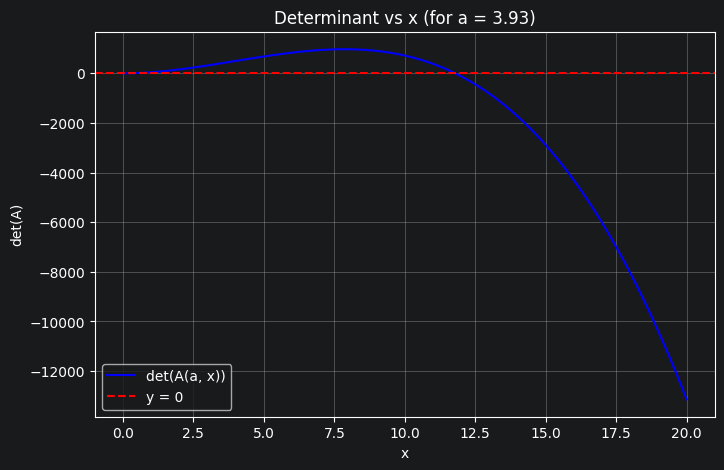

The value of x > 0 where det(A) = 0 is: 11.79


In [30]:
# Solution for problem 5
def matrix_A(a, x):
    return np.array([
        [a + x, a - x, a - x],
        [a - x, a + x, a - x],
        [a - x, a - x, a + x]
    ])

def deter(a,x):
    return np.linalg.det(matrix_A(a, x))

x_num=np.linspace(0, 20, 1000)
y_num=[deter(a, x) for x in x_num]

plt.figure(figsize=(8, 5))
plt.plot(x_num, y_num, label='det(A(a, x))', color='blue')
plt.axhline(0, color='red', linestyle='--', label='y = 0')
plt.grid(True)
plt.xlabel('x')
plt.ylabel('det(A)')
plt.title(f'Determinant vs x (for a = {a})')
plt.legend()
plt.show()

x_solution = 3 * a
print(f"The value of x > 0 where det(A) = 0 is: {x_solution:.2f}")

In [ ]:
# №1 x=3a
# №2 They are directly proportional